In [3]:
import pandas as pd
import numpy as np

df = pd.read_csv("../dataset/final_combined_dataset.csv")

print("Total Records:", len(df))
print("Total Columns:", len(df.columns))
print("Dataset Shape:", df.shape)

print("\nColumn Names:")
print(df.columns.tolist())

display(df.head())

Total Records: 204813
Total Columns: 3
Dataset Shape: (204813, 3)

Column Names:
['target', 'text', 'label']


,target,text,label
0,spam,Congratulations! You've been selected for a lu...,NaN
1,spam,URGENT: Your account has been compromised. Cli...,NaN
2,spam,You've won a free iPhone! Claim your prize by ...,NaN
3,spam,Act now and receive a 50% discount on all purc...,NaN
4,spam,Important notice: Your subscription will expir...,NaN


In [4]:
# Check missing values
print("Missing Values:")
print(df.isnull().sum())

# Check unique values in target
print("\nTarget Values:")
print(df["target"].value_counts(dropna=False))

# Check unique values in label
print("\nLabel Values:")
print(df["label"].value_counts(dropna=False))

# Check duplicate records
print("\nDuplicate Records:", df.duplicated().sum())

# Display last 10 records
print("\nLast 10 Records:")
display(df.tail(10))

Missing Values:
target    193852
text           2
label      10961
dtype: int64

Target Values:
target
NaN     193852
ham       8555
spam      2406
Name: count, dtype: int64

Label Values:
label
Ham     102160
Spam     91692
NaN      10961
Name: count, dtype: int64

Duplicate Records: 674

Last 10 Records:


,target,text,label
204803,NaN,oneok recap report for december any questions ...,Ham
204804,NaN,susan and i are on the case are you still in d...,Ham
204805,NaN,original message from ntops insync net mailto...,Ham
204806,NaN,we are compiling a list of everyone's personal...,Ham
204807,NaN,sorry but once again tim has discovered a bug ...,Ham
204808,NaN,on escapenumber escapenumber escapenumber rob ...,Ham
204809,NaN,we have everything you need escapelong cialesc...,Spam
204810,NaN,hi quick question say i have a date variable i...,Ham
204811,NaN,thank you for your loan request which we recie...,Spam
204812,NaN,this is an automatically generated delivery st...,Ham


In [3]:
# Create a copy of the original dataset
clean_df = df.copy()

# Combine both label columns
clean_df["final_label"] = (
    clean_df["target"]
    .combine_first(clean_df["label"])
    .str.lower()
)

# Identify which original dataset each record came from
clean_df["source"] = np.where(
    clean_df["target"].notna(),
    "Dataset A",
    "Dataset B"
)

# Remove the old label columns from the working copy
clean_df = clean_df.drop(columns=["target", "label"])

# Display results
print("New Dataset Shape:", clean_df.shape)

print("\nFinal Label Distribution:")
print(clean_df["final_label"].value_counts())

print("\nSource Distribution:")
print(clean_df["source"].value_counts())

print("\nMissing Values:")
print(clean_df.isnull().sum())

display(clean_df.head())

New Dataset Shape: (204813, 3)

Final Label Distribution:
final_label
ham     110715
spam     94098
Name: count, dtype: int64

Source Distribution:
source
Dataset B    193852
Dataset A     10961
Name: count, dtype: int64

Missing Values:
text           2
final_label    0
source         0
dtype: int64


,text,final_label,source
0,Congratulations! You've been selected for a lu...,spam,Dataset A
1,URGENT: Your account has been compromised. Cli...,spam,Dataset A
2,You've won a free iPhone! Claim your prize by ...,spam,Dataset A
3,Act now and receive a 50% discount on all purc...,spam,Dataset A
4,Important notice: Your subscription will expir...,spam,Dataset A


In [4]:
# Display 5 random messages from Dataset A
print("DATASET A SAMPLES:")
display(
    clean_df[clean_df["source"] == "Dataset A"]["text"].sample(
        5, random_state=42
    )
)

# Display 5 random messages from Dataset B
print("\nDATASET B SAMPLES:")
display(
    clean_df[clean_df["source"] == "Dataset B"]["text"].sample(
        5, random_state=42
    )
)

DATASET A SAMPLES:


4984     enw meeting / teambuilding event - jillian ' s...
4710     organizational announcement please see attache...
9413     Is it your yahoo boys that bring in the perf? ...
6587     Get 3 Lions England tone, reply lionm 4 mono o...
10418    Yup... I havent been there before... You want ...
Name: text, dtype: str


DATASET B SAMPLES:


147073     a if you don't want this type of e mail pleas...
86938     a full list of news articles will be distribut...
64923     now online with profiles close to escapenumber...
131436    va pv rjgex py cuohox qqo jq poeedj cbqlrvncao...
28640     does size matter' escapenumber of women said t...
Name: text, dtype: str

In [5]:
clean_df["message_length"] = clean_df["text"].str.len()

print(clean_df.groupby("source")["message_length"].describe())

              count         mean           std  min    25%    50%     75%  \
source                                                                      
Dataset A   10961.0   530.314935   1139.178714  1.0   55.0  139.0   491.0   
Dataset B  193850.0  1812.779427  26595.100000  1.0  362.0  800.0  1803.0   

                  max  
source                 
Dataset A     31851.0  
Dataset B  11510306.0  


In [7]:
# Find the 5 longest messages in each dataset

for source in ["Dataset A", "Dataset B"]:

    print("\n", source, "- LONGEST MESSAGES")

    longest = (
        clean_df[clean_df["source"] == source]
        .assign(length=lambda x: x["text"].str.len())
        .nlargest(5, "length")
    )

    for index, row in longest.iterrows():
        print("\nMessage length:", len(row["text"]))
        print("Message:", row["text"][:500])


 Dataset A - LONGEST MESSAGES

Message length: 31851
Message: fw : " red , white and blue out " - - - - - original message - - - - - from : carter , rhonda [ mailto : rcarter @ cooperinst . org ] sent : friday , september 14 , 2001 12 : 33 pm to : ' al _ abbott @ compuserve . com ' ; ' mabner @ sprintmail . com ' ; ' aggiebob @ hotmail . com ' ; ' adamsck @ flash . net ' ; ' gadams @ promus . com ' ; ' pjadell @ yahoo . com ' ; ' bob @ cybersitebuilders . com ' ; ' worml 998 @ hotmail . com ' ; ' janie . beth @ prodigy . net ' ; ' gakin @ mccarthy . com ' 

Message length: 21740
Message: online pharxmacy 80 % off all meds disscount phafrmacy onlsine ! ( grasnd opegning , 80 % off all meds , orfder today at your doorstep tomorrow ! ) weisght lorss meridia mesns heablth viagra visagra st suzper visagra ( ciaslis ) pazin relsief ulztram valisum xadnax prolzac musscle relawxers soma stsop smtoking zyban asnti depreeessant prozac xansax varlium pasxil bypsass all the long lines , place you

In [8]:
# Check how many messages exceed different lengths

for limit in [1000, 5000, 10000, 50000, 100000]:
    count = (clean_df["text"].str.len() > limit).sum()
    print(f"Messages longer than {limit} characters: {count}")

# Display the 10 longest records
clean_df["message_length"] = clean_df["text"].str.len()

display(
    clean_df.nlargest(10, "message_length")[
        ["source", "final_label", "message_length"]
    ]
)

Messages longer than 1000 characters: 84236
Messages longer than 5000 characters: 12370
Messages longer than 10000 characters: 3607
Messages longer than 50000 characters: 237
Messages longer than 100000 characters: 58


,source,final_label,message_length
14298,Dataset B,ham,11510306.0
98894,Dataset B,ham,605878.0
34215,Dataset B,ham,605194.0
34686,Dataset B,ham,598705.0
135717,Dataset B,ham,274682.0
176330,Dataset B,ham,228353.0
166739,Dataset B,ham,225895.0
176530,Dataset B,ham,214986.0
22051,Dataset B,ham,191495.0
150454,Dataset B,ham,186220.0


In [9]:
print("Records with missing text:")
display(clean_df[clean_df["text"].isna()])

Records with missing text:


,text,final_label,source,message_length
58255,NaN,spam,Dataset B,NaN
160175,NaN,ham,Dataset B,NaN


In [10]:
clean_df = clean_df.dropna(subset=["text"]).copy()

print("Dataset shape after removing missing text:")
print(clean_df.shape)

print("\nMissing values:")
print(clean_df.isnull().sum())

Dataset shape after removing missing text:
(204811, 4)

Missing values:
text              0
final_label       0
source            0
message_length    0
dtype: int64


In [11]:
print("Exact duplicate records:")
print(clean_df.duplicated().sum())

print("\nDuplicate messages:")
print(clean_df.duplicated(subset=["text"]).sum())

print("\nMessages with conflicting labels:")
label_check = clean_df.groupby("text")["final_label"].nunique()
print((label_check > 1).sum())

Exact duplicate records:
674

Duplicate messages:
677

Messages with conflicting labels:
3


In [12]:
label_check = clean_df.groupby("text")["final_label"].nunique()

conflicting_texts = label_check[label_check > 1].index

conflicting_records = clean_df[
    clean_df["text"].isin(conflicting_texts)
].sort_values("text")

display(conflicting_records)

,text,final_label,source,message_length
10928,Your Account Was Accessed From a New Device We...,spam,Dataset A,189.0
10929,Your Account Was Accessed From a New Device We...,ham,Dataset A,189.0
44126,hi,spam,Dataset B,2.0
83545,hi,ham,Dataset B,2.0
139736,unsubscribe,spam,Dataset B,11.0
163431,unsubscribe,ham,Dataset B,11.0


In [13]:
# Identify messages with conflicting labels
label_check = clean_df.groupby("text")["final_label"].nunique()
conflicting_texts = label_check[label_check > 1].index

# Remove all records containing conflicting messages
clean_df = clean_df[
    ~clean_df["text"].isin(conflicting_texts)
].copy()

print("Dataset shape after removing conflicts:")
print(clean_df.shape)

print("\nRemaining conflicting messages:")
print(
    (clean_df.groupby("text")["final_label"].nunique() > 1).sum()
)

Dataset shape after removing conflicts:
(204805, 4)

Remaining conflicting messages:
0


In [14]:
print("Duplicates before removal:", clean_df.duplicated().sum())

clean_df = clean_df.drop_duplicates().copy()

print("Dataset shape after removing duplicates:", clean_df.shape)

print("Duplicates remaining:", clean_df.duplicated().sum())

Duplicates before removal: 674
Dataset shape after removing duplicates: (204131, 4)
Duplicates remaining: 0


In [15]:
print("Final label distribution:")
print(clean_df["final_label"].value_counts())

print("\nPercentage distribution:")
print(
    clean_df["final_label"]
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)

Final label distribution:
final_label
ham     110170
spam     93961
Name: count, dtype: int64

Percentage distribution:
final_label
ham     53.97
spam    46.03
Name: proportion, dtype: float64


In [16]:
clean_df.to_csv(
    "../dataset/cleaned_spam_dataset.csv",
    index=False
)

print("Cleaned dataset saved successfully!")

Cleaned dataset saved successfully!


In [17]:
print("Sample spam messages:")
display(
    clean_df[clean_df["final_label"] == "spam"]["text"].sample(5, random_state=42)
)

print("\nSample ham messages:")
display(
    clean_df[clean_df["final_label"] == "ham"]["text"].sample(5, random_state=42)
)

Sample spam messages:


81828     full hard erections long lasting effects promp...
126813     bd cescapenumber ba fescapenumber cescapenumb...
145368    greetings accepting mortgage application bad c...
57342     if you prefer lovvprice medicals just check ou...
167110    dear partner i have a profiling amount in an e...
Name: text, dtype: str


Sample ham messages:


134229    need talk instantaneous supply dealt sand hill...
57787     at the end of tonight's season finalle of smal...
125912    i wasn't old news to me but the triplets of be...
147678    mark could please take look access agreement a...
178932    subject new book language acquisition literacy...
Name: text, dtype: str

In [18]:
# Check special characters and unusual patterns
print("Messages containing HTML tags:")
print(clean_df["text"].str.contains(r"<[^>]+>", regex=True, na=False).sum())

print("\nMessages containing URLs:")
print(clean_df["text"].str.contains(r"https?://|www\.", case=False, regex=True, na=False).sum())

print("\nMessages containing escape patterns:")
print(clean_df["text"].str.contains(r"escapenumber|escape", case=False, regex=True, na=False).sum())

print("\nMessages containing email addresses:")
print(clean_df["text"].str.contains(r"\b[\w.+-]+@[\w.-]+\.[a-zA-Z]{2,}\b", regex=True, na=False).sum())

Messages containing HTML tags:
6

Messages containing URLs:
116

Messages containing escape patterns:
136416

Messages containing email addresses:
18


In [19]:
# Display messages containing escape patterns
escape_samples = clean_df[
    clean_df["text"].str.contains(
        r"escapenumber|escape",
        case=False,
        regex=True,
        na=False
    )
]

print("Total messages:", len(escape_samples))

display(
    escape_samples["text"].sample(
        10,
        random_state=42
    )
)

Total messages: 136416


163300    on jun escapenumber escapenumber escapenumber ...
147606    as requested original message from killen fait...
28795     hha topics may be particularly interesting to ...
151373    i am new to linux not to r and recently instal...
93873     fyi original message velasco jennifer sent mon...
73267      begin pgp signed message hash shaescapenumber...
183051    on tue escapenumber escapenumber escapenumber ...
96536     the planet has gone wireless and mobile airwav...
61364     leave banking concerns fight mortgage company ...
190040    hi i am bored this afternoon i am escapenumber...
Name: text, dtype: str

In [20]:
import re

# Find all words containing "escape"
escape_words = clean_df["text"].str.findall(
    r"\b\w*escape\w*\b"
).explode()

print("Most common escape patterns:")
display(escape_words.value_counts().head(20))

Most common escape patterns:


text
escapenumber      3321635
escapelong         445346
cescapenumber      114904
bescapenumber      110692
aescapenumber       81072
eescapenumber       45481
escapenumberd       42051
descapenumber       42007
fescapenumber       35079
escapenumbere       24830
escapenumbermg      20963
escapenumberth      17652
escapenumbera       12820
escapenumberc       12400
escapenumberb       10742
escapenumberf        8951
zescapenumberr       7515
escapenumbero        7402
vescapenumber        7023
xescapenumber        6911
Name: count, dtype: int64

In [21]:
# Display 5 complete messages containing escape patterns

for message in escape_samples["text"].sample(5, random_state=10):
    print("--------------------------------")
    print(message[:1000])

--------------------------------
meine damen und herren wie es bekannt ist bewegt sich der aktienkurs bei kleinen gesellschaften viel staerker und schneller als bei großen gesellschaften da reicht ein neues produkt und der aktienkurs explodiert die kronos media ag wkn escapelong isin ch escapenumber mit sitz in der schweiz und tochter und partnerunternehmen in deutschland investiert in produktion von filmen genauso wie in neue ideen fuer interaktive und mobile inhalte in einem schnell wachsenden markt fernsehen kino internet und handyfilme usw medien die gute geschichten erzaehlen erreichen ihre zuschauer und zuhoerer ueberall auf der welt geschichten bei denen man anteil nehmen mitfuehlen mitfiebern kann die fachleute hinter kronos media verfuegen ueber langjaehrige erfahrung im bereich von filmgestaltung und produktion medienkampagnen und weltweiten vertrieb am escapenumber mai fand die premiere von einem ergreifenden film ueber hannibals elefanten statt uberraschendes projekt ob d

In [23]:
import re
from collections import Counter

escape_counts = Counter()

for message in escape_samples["text"]:
    patterns = re.findall(r"\b\w*escape\w*\b", message)
    escape_counts.update(patterns)

print("Most common escape patterns:")

for pattern, count in escape_counts.most_common(30):
    print(pattern, ":", count)

Most common escape patterns:
escapenumber : 3321635
escapelong : 445346
cescapenumber : 114904
bescapenumber : 110692
aescapenumber : 81072
eescapenumber : 45481
escapenumberd : 42051
descapenumber : 42007
fescapenumber : 35079
escapenumbere : 24830
escapenumbermg : 20963
escapenumberth : 17652
escapenumbera : 12820
escapenumberc : 12400
escapenumberb : 10742
escapenumberf : 8951
zescapenumberr : 7515
escapenumbero : 7402
vescapenumber : 7023
xescapenumber : 6911
escapenumberpm : 5838
ffffffcescapenumber : 5466
ffffffbescapenumber : 5324
escapenumbers : 4352
escapenumberm : 4090
rescapenumber : 3947
uintescapenumber : 3875
pescapenumber : 3854
mescapenumber : 3761
csescapenumber : 3546


In [24]:
clean_df["has_escape"] = clean_df["text"].str.contains(
    "escape",
    case=False,
    regex=False,
    na=False
)

escape_distribution = pd.crosstab(
    clean_df["final_label"],
    clean_df["has_escape"],
    normalize="index"
) * 100

display(escape_distribution)

has_escape,False,True
final_label,,
ham,32.107652,67.892348
spam,34.420664,65.579336


In [25]:
import re

number_pattern_count = clean_df["text"].str.count(
    r"escapenumber|escapelong"
).sum()

print("Total number of occurrences:", number_pattern_count)

Total number of occurrences: 4812285


In [26]:
clean_df["text"] = clean_df["text"].str.replace(
    r"escapenumber|escapelong",
    "numbertoken",
    regex=True,
    case=False
)

print("Replacement completed!")

print(
    "Remaining main escape patterns:",
    clean_df["text"].str.contains(
        r"escapenumber|escapelong",
        case=False,
        regex=True,
        na=False
    ).sum()
)

Replacement completed!
Remaining main escape patterns: 0


In [27]:
remaining_escape = Counter()

for message in clean_df["text"]:
    patterns = re.findall(
        r"\b\w*escape\w*\b",
        message,
        flags=re.IGNORECASE
    )
    remaining_escape.update(patterns)

print("Remaining escape patterns:")
for pattern, count in remaining_escape.most_common(20):
    print(pattern, ":", count)

Remaining escape patterns:
escape : 1022
escaped : 195
escapes : 158
unescape : 64
escapee : 20
unitedescapes : 12
escapees : 8
unescaped : 8
kaleidescape : 6
escapescruise : 3
strescape : 3
allowescapes : 2
sescape : 1
itsescape : 1
refusesescapees : 1
likeescapees : 1
backescapees : 1
escapehtml : 1
runescape : 1
escapenonetext : 1


In [28]:
html_messages = clean_df[
    clean_df["text"].str.contains(
        r"<[^>]+>",
        regex=True,
        na=False
    )
]

print("Messages containing HTML:", len(html_messages))

for message in html_messages["text"]:
    print("\n--------------------------")
    print(message[:1000])

Messages containing HTML: 6

--------------------------
<Forwarded from 448712404000>Please CALL 08712404000 immediately as there is an urgent message waiting for you.

--------------------------
<Forwarded from 88877>FREE entry into our �250 weekly comp just send the word ENTER to 88877 NOW. 18 T&C www.textcomp.com

--------------------------
<Forwarded from 21870000>Hi - this is your Mailbox Messaging SMS alert. You have 4 messages. You have 21 matches. Please call back on 09056242159 to retrieve your messages and matches

--------------------------
<Forwarded from 21870000>Hi - this is your Mailbox Messaging SMS alert. You have 40 matches. Please call back on 09056242159 to retrieve your messages and matches cc100p/min

--------------------------
URGENT! Your Mobile number has been awarded a <UKP>2000 prize GUARANTEED. Call 09061790125 from landline. Claim 3030. Valid 12hrs only 150ppm

--------------------------
PRIVATE! Your 2003 Account Statement for <fone no> shows 800 un-redeem

In [29]:
clean_df = clean_df.drop(columns=["has_escape"], errors="ignore")

clean_df.to_csv(
    "../dataset/cleaned_spam_dataset.csv",
    index=False
)

print("Updated cleaned dataset saved successfully!")
print("Final shape:", clean_df.shape)

Updated cleaned dataset saved successfully!
Final shape: (204131, 4)


In [30]:
print("Dataset shape:")
print(clean_df.shape)

print("\nColumn names:")
print(clean_df.columns.tolist())

print("\nData types:")
print(clean_df.dtypes)

print("\nMissing values:")
print(clean_df.isnull().sum())

print("\nLabel distribution:")
print(clean_df["final_label"].value_counts())

print("\nSample records:")
display(clean_df.head())

Dataset shape:
(204131, 4)

Column names:
['text', 'final_label', 'source', 'message_length']

Data types:
text                  str
final_label           str
source                str
message_length    float64
dtype: object

Missing values:
text              0
final_label       0
source            0
message_length    0
dtype: int64

Label distribution:
final_label
ham     110170
spam     93961
Name: count, dtype: int64

Sample records:


,text,final_label,source,message_length
0,Congratulations! You've been selected for a lu...,spam,Dataset A,90.0
1,URGENT: Your account has been compromised. Cli...,spam,Dataset A,89.0
2,You've won a free iPhone! Claim your prize by ...,spam,Dataset A,72.0
3,Act now and receive a 50% discount on all purc...,spam,Dataset A,72.0
4,Important notice: Your subscription will expir...,spam,Dataset A,94.0


In [31]:
from sklearn.model_selection import train_test_split

# Update message lengths after text cleaning
clean_df["message_length"] = clean_df["text"].str.len()

# Input messages and target labels
X = clean_df["text"]
y = clean_df["final_label"]

# Split into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training messages:", len(X_train))
print("Testing messages:", len(X_test))

print("\nTraining label distribution:")
print(y_train.value_counts())

print("\nTesting label distribution:")
print(y_test.value_counts())

Training messages: 163304
Testing messages: 40827

Training label distribution:
final_label
ham     88136
spam    75168
Name: count, dtype: int64

Testing label distribution:
final_label
ham     22034
spam    18793
Name: count, dtype: int64


In [32]:
from sklearn.feature_extraction.text import TfidfVectorizer

# Create TF-IDF vectorizer
tfidf = TfidfVectorizer(
    max_features=10000,
    stop_words="english",
    ngram_range=(1, 2),
    min_df=2,
    max_df=0.95,
    sublinear_tf=True
)

# Learn from training messages
X_train_tfidf = tfidf.fit_transform(X_train)

# Transform testing messages
X_test_tfidf = tfidf.transform(X_test)

print("Training data shape:", X_train_tfidf.shape)
print("Testing data shape:", X_test_tfidf.shape)
print("Number of features:", len(tfidf.get_feature_names_out()))

Training data shape: (163304, 10000)
Testing data shape: (40827, 10000)
Number of features: 10000


In [33]:
from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import accuracy_score, classification_report

# Create model
nb_model = MultinomialNB()

# Train model
nb_model.fit(X_train_tfidf, y_train)

# Make predictions
nb_predictions = nb_model.predict(X_test_tfidf)

# Calculate accuracy
nb_accuracy = accuracy_score(y_test, nb_predictions)

print("Naive Bayes Accuracy:", round(nb_accuracy * 100, 2), "%")

print("\nClassification Report:")
print(classification_report(y_test, nb_predictions))

Naive Bayes Accuracy: 93.64 %

Classification Report:
              precision    recall  f1-score   support

         ham       0.93      0.95      0.94     22034
        spam       0.94      0.92      0.93     18793

    accuracy                           0.94     40827
   macro avg       0.94      0.94      0.94     40827
weighted avg       0.94      0.94      0.94     40827



In [36]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report

# Create model
lr_model = LogisticRegression(max_iter=1000)

# Train model
lr_model.fit(X_train_tfidf, y_train)

# Make predictions
lr_predictions = lr_model.predict(X_test_tfidf)

# Calculate accuracy
lr_accuracy = accuracy_score(y_test, lr_predictions)

print("Logistic Regression Accuracy:", round(lr_accuracy * 100, 2), "%")

print("\nClassification Report:")
print(classification_report(y_test, lr_predictions))

Logistic Regression Accuracy: 96.78 %

Classification Report:
              precision    recall  f1-score   support

         ham       0.98      0.96      0.97     22034
        spam       0.96      0.97      0.97     18793

    accuracy                           0.97     40827
   macro avg       0.97      0.97      0.97     40827
weighted avg       0.97      0.97      0.97     40827



In [37]:
from sklearn.svm import LinearSVC
from sklearn.metrics import accuracy_score, classification_report

# Create model
svm_model = LinearSVC()

# Train model
svm_model.fit(X_train_tfidf, y_train)

# Make predictions
svm_predictions = svm_model.predict(X_test_tfidf)

# Calculate accuracy
svm_accuracy = accuracy_score(y_test, svm_predictions)

print("SVM Accuracy:", round(svm_accuracy * 100, 2), "%")

print("\nClassification Report:")
print(classification_report(y_test, svm_predictions))

SVM Accuracy: 97.36 %

Classification Report:
              precision    recall  f1-score   support

         ham       0.98      0.97      0.98     22034
        spam       0.97      0.98      0.97     18793

    accuracy                           0.97     40827
   macro avg       0.97      0.97      0.97     40827
weighted avg       0.97      0.97      0.97     40827



In [38]:
import pandas as pd

model_comparison = pd.DataFrame({
    "Model": [
        "Multinomial Naive Bayes",
        "Logistic Regression",
        "SVM"
    ],
    "Accuracy (%)": [
        nb_accuracy * 100,
        lr_accuracy * 100,
        svm_accuracy * 100
    ]
})

model_comparison = model_comparison.sort_values(
    by="Accuracy (%)",
    ascending=False
)

display(model_comparison)

,Model,Accuracy (%)
2,SVM,97.364489
1,Logistic Regression,96.781542
0,Multinomial Naive Bayes,93.639013


In [39]:
from sklearn.model_selection import GridSearchCV
from sklearn.svm import LinearSVC

# Define SVM parameters to test
param_grid = {
    "C": [0.1, 1, 10]
}

# Create GridSearchCV
grid_search = GridSearchCV(
    LinearSVC(),
    param_grid,
    cv=3,
    scoring="f1_macro",
    n_jobs=1,
    verbose=1
)

# Perform tuning using training data only
grid_search.fit(X_train_tfidf, y_train)

# Display best parameters
print("Best Parameters:", grid_search.best_params_)

print(
    "Best Cross-Validation Score:",
    round(grid_search.best_score_ * 100, 2),
    "%"
)

Fitting 3 folds for each of 3 candidates, totalling 9 fits
Best Parameters: {'C': 1}
Best Cross-Validation Score: 97.21 %


In [40]:
from sklearn.metrics import accuracy_score, classification_report

# Get the best tuned SVM model
best_svm_model = grid_search.best_estimator_

# Make predictions on test data
tuned_predictions = best_svm_model.predict(X_test_tfidf)

# Calculate test accuracy
tuned_accuracy = accuracy_score(y_test, tuned_predictions)

print("Tuned SVM Accuracy:", round(tuned_accuracy * 100, 2), "%")

# Display classification report
print("\nClassification Report:")
print(classification_report(y_test, tuned_predictions))

Tuned SVM Accuracy: 97.36 %

Classification Report:
              precision    recall  f1-score   support

         ham       0.98      0.97      0.98     22034
        spam       0.97      0.98      0.97     18793

    accuracy                           0.97     40827
   macro avg       0.97      0.97      0.97     40827
weighted avg       0.97      0.97      0.97     40827



In [41]:
final_results = pd.DataFrame({
    "Model": [
        "Multinomial Naive Bayes",
        "Logistic Regression",
        "Original SVM",
        "Tuned SVM"
    ],
    "Accuracy (%)": [
        nb_accuracy * 100,
        lr_accuracy * 100,
        svm_accuracy * 100,
        tuned_accuracy * 100
    ]
})

final_results = final_results.sort_values(
    by="Accuracy (%)",
    ascending=False
)

display(final_results)

,Model,Accuracy (%)
3,Tuned SVM,97.364489
2,Original SVM,97.364489
1,Logistic Regression,96.781542
0,Multinomial Naive Bayes,93.639013


Matplotlib is building the font cache; this may take a moment.


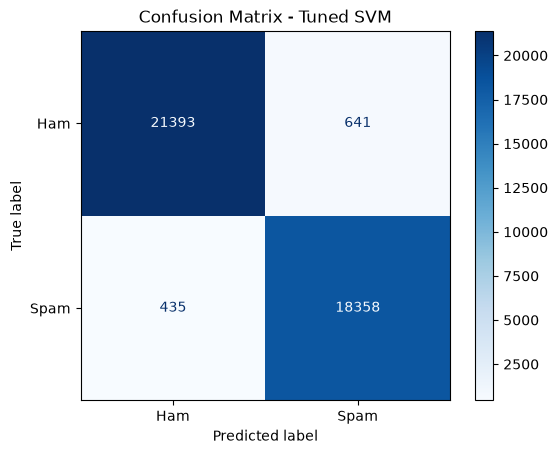

Confusion Matrix:
[[21393   641]
 [  435 18358]]


In [42]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

# Generate confusion matrix
cm = confusion_matrix(
    y_test,
    tuned_predictions,
    labels=["ham", "spam"]
)

# Display confusion matrix
display_cm = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Ham", "Spam"]
)

display_cm.plot(cmap="Blues")
plt.title("Confusion Matrix - Tuned SVM")
plt.show()

print("Confusion Matrix:")
print(cm)

In [44]:
import joblib
import os

# Create models folder if it does not exist
os.makedirs("../models", exist_ok=True)

# Save the trained SVM model
joblib.dump(best_svm_model, "../models/spam_svm_model.pkl")

# Save the TF-IDF vectorizer
joblib.dump(tfidf, "../models/tfidf_vectorizer.pkl")

print("Model and vectorizer saved successfully!")

Model and vectorizer saved successfully!


In [45]:
import joblib

# Load saved model and vectorizer
loaded_model = joblib.load("../models/spam_svm_model.pkl")
loaded_tfidf = joblib.load("../models/tfidf_vectorizer.pkl")

# Test messages
messages = [
    "Congratulations! You have won a free prize. Click here now!",
    "Hi, are you coming to university tomorrow?"
]

# Convert messages into TF-IDF
message_vectors = loaded_tfidf.transform(messages)

# Predict messages
predictions = loaded_model.predict(message_vectors)

# Display results
for message, prediction in zip(messages, predictions):
    print("Message:", message)
    print("Prediction:", prediction.upper())
    print("-----------------------------")

Message: Congratulations! You have won a free prize. Click here now!
Prediction: SPAM
-----------------------------
Message: Hi, are you coming to university tomorrow?
Prediction: HAM
-----------------------------
